# Duka Electronics | H1 2026 board story

## Storyboard — before any plotting code

- **Audience:** Duka Electronics board members; non-technical, time-poor, and likely to read the report on a phone.
- **Decision they own:** Where to focus second-half inventory and marketing investment, and whether to authorize a measured online-growth pilot.
- **Big Idea:** H1 sales recovered strongly from February, but the KES 52.46M result is uneven: Computing contributes almost half of revenue and online orders have a higher average basket. Protect core Computing availability and test targeted online growth rather than spreading investment uniformly.
- **Situation:** The business recorded 1,000 orders and KES 52.46M in sales between January and June 2026.
- **Complication:** June revenue was 64% above February, but Computing generated 48.6% of sales; branch results and channel basket values differ.
- **Resolution:** Protect Computing stock, approve a measured 90-day online campaign pilot, and review monthly revenue, average order value, and category mix by branch before scaling.

## Definitions and source

The source is the supplied synthetic `duka_sales.csv`. Revenue is units sold multiplied by unit price; values are Kenyan shillings (KES). Average order value is total revenue divided by the number of order records. Channel and branch comparisons are descriptive and do not establish cause and effect.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import display

DATA_PATH = Path("duka_sales.csv")
REPORT_DIR = Path("reports")
FIGURE_DIR = Path("figures")
REPORT_DIR.mkdir(exist_ok=True)
FIGURE_DIR.mkdir(exist_ok=True)

data = pd.read_csv(DATA_PATH, parse_dates=["order_date"])
data["revenue"] = data["units_sold"] * data["unit_price"]
data["month"] = data["order_date"].dt.to_period("M")

PALETTE = {
    "ink": "#17324D",
    "blue": "#3478A6",
    "highlight": "#E76F51",
    "muted": "#B8C5D1",
    "grid": "#E5EAF0",
    "paper": "#FFFFFF",
}
SOURCE = "Source: Duka Electronics order data, Jan–Jun 2026"
sns.set_theme(style="white", context="notebook")
plt.rcParams.update({"font.family": "DejaVu Sans", "axes.titleweight": "bold"})

assert data["order_id"].is_unique
assert data[["order_date", "branch", "category", "channel", "units_sold", "unit_price"]].notna().all().all()
assert data["order_date"].between("2026-01-01", "2026-06-30").all()
data.head()


,order_id,order_date,branch,region,product,category,channel,units_sold,unit_price,revenue,month
0,DUKA-0001,2026-03-24,Mombasa,Coast,Smart Watch,Wearables,Online,1,23100,23100,2026-03
1,DUKA-0002,2026-06-07,Nairobi,Capital,Laptop Pro 14,Computing,In-store,4,118900,475600,2026-06
2,DUKA-0003,2026-05-15,Nairobi,Capital,Smartphone X,Mobile,In-store,2,39700,79400,2026-05
3,DUKA-0004,2026-02-18,Thika,Central,HD Television 32in,Television,In-store,3,26600,79800,2026-02
4,DUKA-0005,2026-04-16,Kisumu,Western,Wireless Headphones,Audio,In-store,1,8400,8400,2026-04


In [2]:
total_revenue = data["revenue"].sum()
order_count = data["order_id"].nunique()
average_order_value = total_revenue / order_count

monthly = (
    data.groupby("month", observed=True)
    .agg(revenue=("revenue", "sum"), orders=("order_id", "nunique"))
    .reset_index()
)
monthly["month_label"] = monthly["month"].dt.strftime("%b")
branch_revenue = data.groupby("branch")["revenue"].sum().sort_values(ascending=False)
category_revenue = data.groupby("category")["revenue"].sum().sort_values(ascending=False)
channel_metrics = data.groupby("channel").agg(
    revenue=("revenue", "sum"),
    orders=("order_id", "nunique"),
)
channel_metrics["average_order_value"] = channel_metrics["revenue"] / channel_metrics["orders"]

low_month = monthly.loc[monthly["revenue"].idxmin()]
high_month = monthly.loc[monthly["revenue"].idxmax()]
recovery_pct = (high_month["revenue"] / low_month["revenue"] - 1) * 100
computing_share = category_revenue["Computing"] / total_revenue
online_aov_lift = (
    channel_metrics.loc["Online", "average_order_value"]
    / channel_metrics.loc["In-store", "average_order_value"]
    - 1
) * 100

print(f"Orders: {order_count:,} | H1 revenue: KES {total_revenue:,.0f}")
print(f"Average order value: KES {average_order_value:,.0f}")
print(f"{high_month['month_label']} revenue is {recovery_pct:.1f}% above the {low_month['month_label']} low.")
print(f"Computing share: {computing_share:.1%} | Online AOV lift: {online_aov_lift:.1f}%")


Orders: 1,000 | H1 revenue: KES 52,464,100
Average order value: KES 52,464
Jun revenue is 64.1% above the Feb low.
Computing share: 48.6% | Online AOV lift: 7.5%


## Board report

Four views establish the sales recovery, compare branches, show category concentration, and quantify the channel basket-value difference. Titles are generated from the calculated metrics. All monetary labels are KES (or KES millions), and each chart names its source.


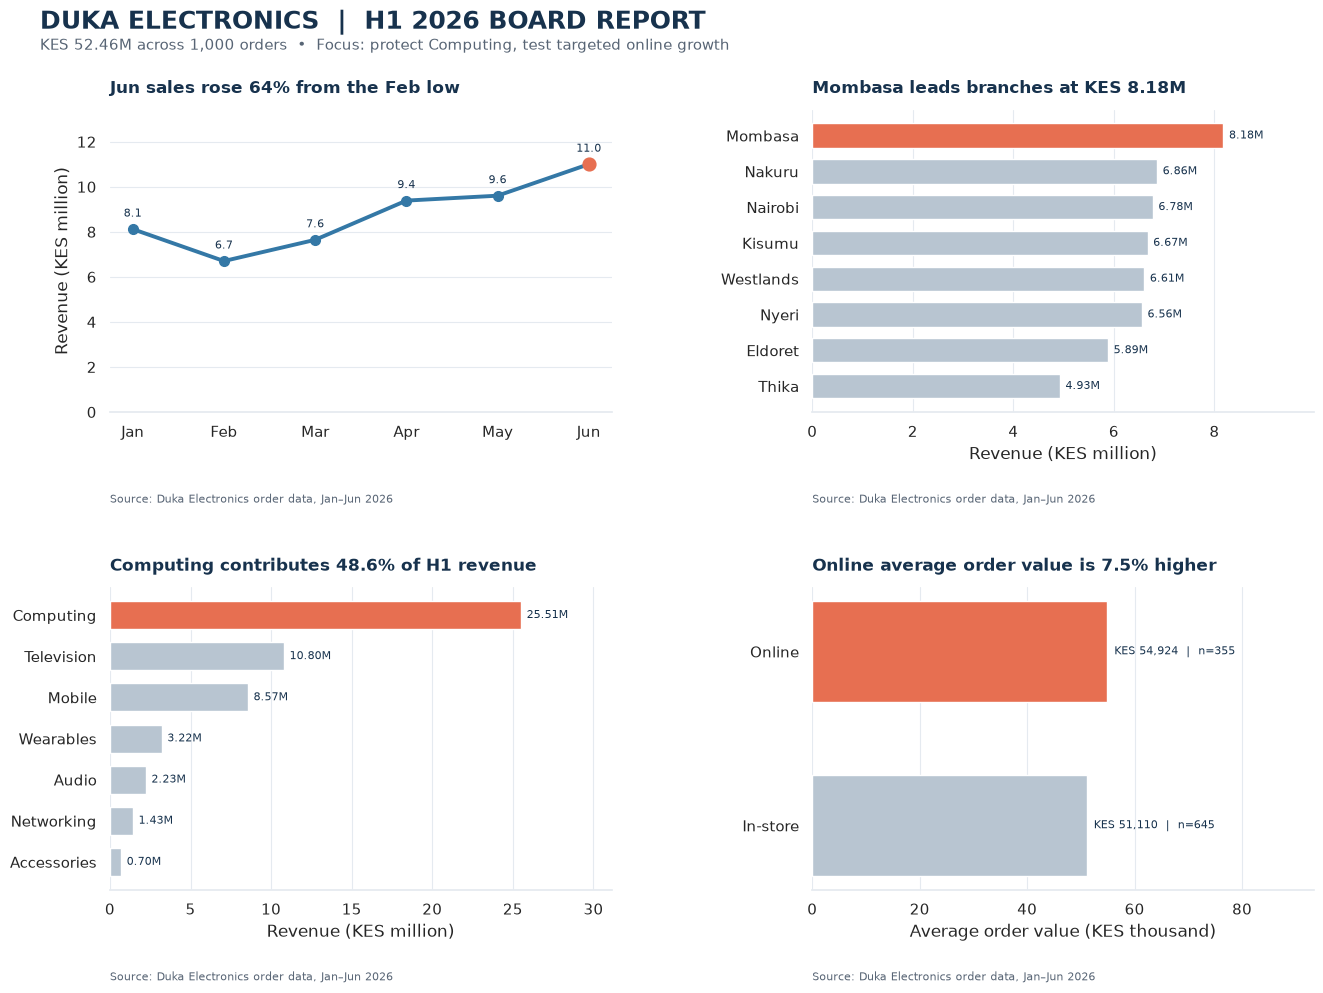

Saved one-page report to reports\duka_board_report.png


In [3]:
def add_source(ax):
    ax.text(
        0,
        -0.27,
        SOURCE,
        transform=ax.transAxes,
        ha="left",
        va="top",
        fontsize=8,
        color="#586575",
    )


fig, axes = plt.subplots(2, 2, figsize=(14, 10), facecolor=PALETTE["paper"])
fig.suptitle(
    "DUKA ELECTRONICS  |  H1 2026 BOARD REPORT",
    x=0.06,
    y=0.98,
    ha="left",
    fontsize=18,
    fontweight="bold",
    color=PALETTE["ink"],
)
fig.text(
    0.06,
    0.94,
    f"KES {total_revenue / 1e6:.2f}M across {order_count:,} orders"
    "  •  Focus: protect Computing, test targeted online growth",
    ha="left",
    fontsize=11,
    color="#586575",
)

# 1. Monthly trend
ax = axes[0, 0]
monthly_m = monthly["revenue"] / 1e6
ax.plot(monthly["month_label"], monthly_m, color=PALETTE["blue"], linewidth=2.8, marker="o", markersize=7)
ax.scatter([high_month["month_label"]], [high_month["revenue"] / 1e6], color=PALETTE["highlight"], s=85, zorder=3)
for _, row in monthly.iterrows():
    ax.annotate(
        f"{row['revenue'] / 1e6:.1f}",
        (row["month_label"], row["revenue"] / 1e6),
        xytext=(0, 9),
        textcoords="offset points",
        ha="center",
        fontsize=8,
        color=PALETTE["ink"],
    )
ax.set_title(
    f"{high_month['month_label']} sales rose {recovery_pct:.0f}% from the {low_month['month_label']} low",
    loc="left",
    fontsize=12,
    color=PALETTE["ink"],
    pad=12,
)
ax.set_ylabel("Revenue (KES million)")
ax.set_xlabel("")
ax.set_ylim(0, monthly_m.max() * 1.22)
ax.grid(axis="y", color=PALETTE["grid"], linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.spines["bottom"].set_color(PALETTE["grid"])
add_source(ax)

# 2. Sorted branch comparison
ax = axes[0, 1]
ordered_branches = branch_revenue.sort_values()
branch_colors = [
    PALETTE["highlight"] if name == branch_revenue.idxmax() else PALETTE["muted"]
    for name in ordered_branches.index
]
bars = ax.barh(ordered_branches.index, ordered_branches / 1e6, color=branch_colors, height=0.68)
ax.bar_label(bars, labels=[f"{value:.2f}M" for value in ordered_branches / 1e6], padding=4, fontsize=8, color=PALETTE["ink"])
ax.set_title(
    f"{branch_revenue.idxmax()} leads branches at KES {branch_revenue.max() / 1e6:.2f}M",
    loc="left",
    fontsize=12,
    color=PALETTE["ink"],
    pad=12,
)
ax.set_xlabel("Revenue (KES million)")
ax.set_ylabel("")
ax.set_xlim(0, ordered_branches.max() / 1e6 * 1.22)
ax.grid(axis="x", color=PALETTE["grid"], linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.spines["bottom"].set_color(PALETTE["grid"])
add_source(ax)

# 3. Category composition
ax = axes[1, 0]
ordered_categories = category_revenue.sort_values()
category_colors = [
    PALETTE["highlight"] if name == "Computing" else PALETTE["muted"]
    for name in ordered_categories.index
]
bars = ax.barh(ordered_categories.index, ordered_categories / 1e6, color=category_colors, height=0.68)
ax.bar_label(bars, labels=[f"{value:.2f}M" for value in ordered_categories / 1e6], padding=4, fontsize=8, color=PALETTE["ink"])
ax.set_title(
    f"Computing contributes {computing_share:.1%} of H1 revenue",
    loc="left",
    fontsize=12,
    color=PALETTE["ink"],
    pad=12,
)
ax.set_xlabel("Revenue (KES million)")
ax.set_ylabel("")
ax.set_xlim(0, ordered_categories.max() / 1e6 * 1.22)
ax.grid(axis="x", color=PALETTE["grid"], linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.spines["bottom"].set_color(PALETTE["grid"])
add_source(ax)

# 4. Average order value by channel
ax = axes[1, 1]
channel_order = channel_metrics["average_order_value"].sort_values()
channel_colors = [
    PALETTE["highlight"] if name == "Online" else PALETTE["muted"]
    for name in channel_order.index
]
bars = ax.barh(channel_order.index, channel_order / 1000, color=channel_colors, height=0.58)
channel_labels = [
    f"KES {channel_metrics.loc[name, 'average_order_value']:,.0f}  |  n={int(channel_metrics.loc[name, 'orders']):,}"
    for name in channel_order.index
]
ax.bar_label(bars, labels=channel_labels, padding=5, fontsize=8, color=PALETTE["ink"])
ax.set_title(
    f"Online average order value is {online_aov_lift:.1f}% higher",
    loc="left",
    fontsize=12,
    color=PALETTE["ink"],
    pad=12,
)
ax.set_xlabel("Average order value (KES thousand)")
ax.set_ylabel("")
ax.set_xlim(0, channel_order.max() / 1000 * 1.7)
ax.grid(axis="x", color=PALETTE["grid"], linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.spines["bottom"].set_color(PALETTE["grid"])
add_source(ax)

fig.subplots_adjust(left=0.11, right=0.97, top=0.88, bottom=0.10, hspace=0.58, wspace=0.40)
report_path = REPORT_DIR / "duka_board_report.png"
fig.savefig(report_path, dpi=240, bbox_inches="tight", facecolor=fig.get_facecolor())
display(fig)
print(f"Saved one-page report to {report_path}")
plt.close(fig)


## Before-and-after: branch revenue comparison

The baseline below is deliberately representative of a quick exploratory chart, not the final board design. The revised chart reuses the same branch-revenue data and metric as the report.

- **Sorting:** changed from source-row order to descending revenue, making the ranking and spread easier to scan.
- **Orientation:** changed vertical, angled labels to horizontal bars so all branch names remain readable on a phone.
- **Colour:** replaced multiple default colours with muted bars and one highlight for the leading branch.
- **Labels and context:** added direct KES values, explicit KES-million units, an insight title computed from the data, and a source line.
- **Clutter:** removed dense gridlines and unnecessary frame edges; retained only subtle value-axis guides.


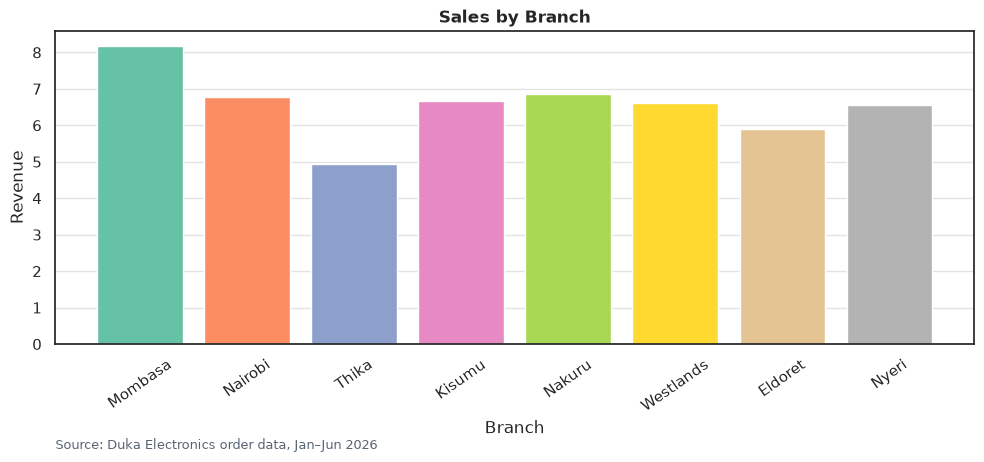

Saved baseline chart to figures\before.png


In [4]:
# Before: generic title, source-row order, rotated labels, multiple colours, and dense grid.
before_order = branch_revenue.reindex(data["branch"].drop_duplicates())
fig, ax = plt.subplots(figsize=(10, 5), facecolor="white")
ax.bar(before_order.index, before_order / 1e6, color=sns.color_palette("Set2", n_colors=len(before_order)))
ax.set_title("Sales by Branch")
ax.set_ylabel("Revenue")
ax.set_xlabel("Branch")
ax.tick_params(axis="x", labelrotation=35)
ax.grid(axis="y", alpha=0.55)
ax.set_axisbelow(True)
ax.text(
    0,
    -0.30,
    SOURCE,
    transform=ax.transAxes,
    ha="left",
    va="top",
    fontsize=9,
    color="#586575",
)
fig.tight_layout()
before_path = FIGURE_DIR / "before.png"
fig.savefig(before_path, dpi=180, bbox_inches="tight")
display(fig)
plt.close(fig)
print(f"Saved baseline chart to {before_path}")


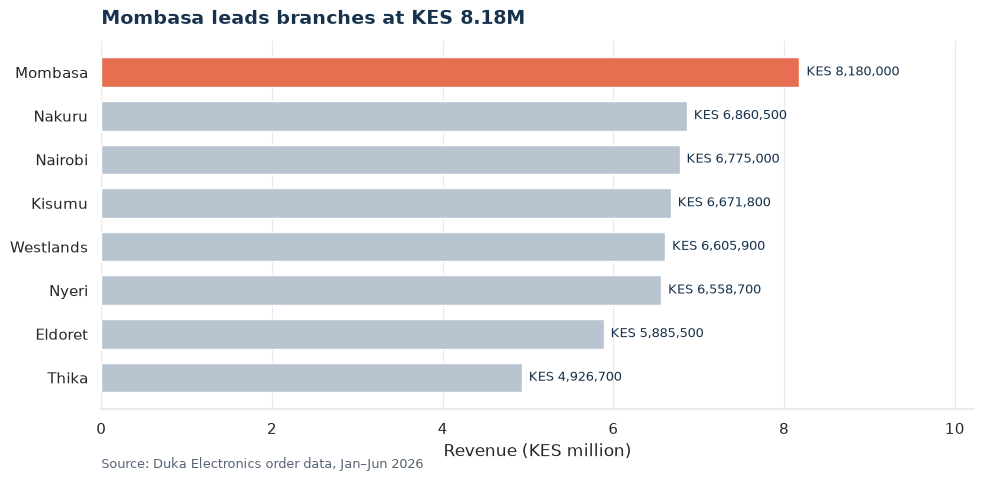

Saved revised chart to figures\after.png


In [5]:
# After: sorted horizontal bars, one leader highlight, direct values, labelled units, and a data-led title.
ordered_branches = branch_revenue.sort_values()
colors = [
    PALETTE["highlight"] if name == branch_revenue.idxmax() else PALETTE["muted"]
    for name in ordered_branches.index
]
fig, ax = plt.subplots(figsize=(10, 5), facecolor="white")
bars = ax.barh(ordered_branches.index, ordered_branches / 1e6, color=colors, height=0.68)
ax.bar_label(bars, labels=[f"KES {value:,.0f}" for value in ordered_branches], padding=5, fontsize=9, color=PALETTE["ink"])
ax.set_title(
    f"{branch_revenue.idxmax()} leads branches at KES {branch_revenue.max() / 1e6:.2f}M",
    loc="left",
    fontsize=14,
    color=PALETTE["ink"],
    pad=12,
)
ax.set_xlabel("Revenue (KES million)")
ax.set_ylabel("")
ax.set_xlim(0, ordered_branches.max() / 1e6 * 1.25)
ax.grid(axis="x", color=PALETTE["grid"], linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.spines["bottom"].set_color(PALETTE["grid"])
ax.text(0, -0.13, SOURCE, transform=ax.transAxes, ha="left", va="top", fontsize=9, color="#586575")
fig.tight_layout()
after_path = FIGURE_DIR / "after.png"
fig.savefig(after_path, dpi=200, bbox_inches="tight")
display(fig)
plt.close(fig)
print(f"Saved revised chart to {after_path}")


## Board Summary

First-half sales reached KES 52.46 million across 1,000 orders, averaging KES 52,464 per order. Momentum improved after February’s KES 6.70 million low: June reached KES 11.00 million, up 64% from February. The recovery was not evenly distributed. Computing generated KES 25.51 million, or 48.6% of revenue, making stock availability in this category a priority. Mombasa led branches with KES 8.18 million, while Thika recorded KES 4.93 million; branch results therefore warrant targeted follow-up rather than a national assumption. Online orders averaged KES 54,924, 7.5% above in-store orders, although stores contributed more total revenue. This difference is descriptive, not proof that online marketing caused higher baskets. We recommend protecting Computing availability and approving a measured 90-day online campaign pilot. Track revenue, average order value, and category mix by branch against a baseline before expanding. Review pilot results at the next board meeting, and adjust stock and marketing allocation using comparable performance.

**Word count: 150.**
